# **Week 7: Student Performance Data Understanding, Cleaning and Feature Engineering**

Step 1: Import required libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Step 2: Upload the dataset

In [2]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/StudentsPerformance.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


Step 3: Understand the dataset

In [3]:
# Display first five records

print("First Five Records:")
display(df.head())

# Display last five records

print("\nLast Five Records:")
display(df.tail())

# Dataset dimensions

print("\nDataset Shape:", df.shape)

# Column names

print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information

print("\nDataset Information:")
df.info()

# Data types

print("\nData Types:")
print(df.dtypes)

First Five Records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Last Five Records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86



Dataset Shape: (1000, 8)

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Data Types:
gender                         object
race/ethnicity  

Step 4: Standardize column names

In [4]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("/", "_")
)

print("Updated Column Names:")
print(df.columns.tolist())

Updated Column Names:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


Step 5: Check missing values

In [5]:
print("Missing Values:")
print(df.isnull().sum())

# Calculate missing value percentage

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

Missing Values:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Missing Value Percentage:
gender                         0.0
race_ethnicity                 0.0
parental_level_of_education    0.0
lunch                          0.0
test_preparation_course        0.0
math_score                     0.0
reading_score                  0.0
writing_score                  0.0
dtype: float64


Step 6: Check duplicate records

In [6]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

Number of Duplicate Records: 0


Step 7: Clean categorical columns

In [7]:
categorical_columns = [
    "gender",
    "race_ethnicity",
    "parental_level_of_education",
    "lunch",
    "test_preparation_course"
]

# Remove unwanted spaces and standardize text

for col in categorical_columns:

    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

print("Categorical columns cleaned successfully!")

display(df[categorical_columns].head())

Categorical columns cleaned successfully!


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course
0,Female,Group B,Bachelor'S Degree,Standard,None
1,Female,Group C,Some College,Standard,Completed
2,Female,Group B,Master'S Degree,Standard,None
3,Male,Group A,Associate'S Degree,Free/Reduced,None
4,Male,Group C,Some College,Standard,None


Step 8: Convert score columns into numeric format

In [8]:
# Define subject score columns

score_columns = [
    "math_score",
    "reading_score",
    "writing_score"
]

# Convert scores into numeric data types

for col in score_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("Score columns converted successfully!")

print(df[score_columns].dtypes)

Score columns converted successfully!
math_score       int64
reading_score    int64
writing_score    int64
dtype: object


In [9]:
print("Missing Values in Subject Scores:")

print(df[score_columns].isnull().sum())

Missing Values in Subject Scores:
math_score       0
reading_score    0
writing_score    0
dtype: int64


Step 9: Validate score ranges

In [11]:
# Check invalid score values

for col in score_columns:

    invalid_count = (
        (df[col] < 0) | (df[col] > 100)
    ).sum()

    print(f"{col}: {invalid_count} invalid values")

math_score: 0 invalid values
reading_score: 0 invalid values
writing_score: 0 invalid values


Step 10: Calculate descriptive statistics

In [12]:
# Generate descriptive statistics

score_statistics = df[score_columns].describe()

display(score_statistics)

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [14]:
for col in score_columns:

    print("\nSubject:", col.upper())

    print("Mean:", df[col].mean())

    print("Median:", df[col].median())

    print("Standard Deviation:", df[col].std())

    print("Minimum:", df[col].min())

    print("Maximum:", df[col].max())

    print("Variance:", df[col].var())


Subject: MATH_SCORE
Mean: 66.089
Median: 66.0
Standard Deviation: 15.163080096009468
Minimum: 0
Maximum: 100
Variance: 229.91899799799847

Subject: READING_SCORE
Mean: 69.169
Median: 70.0
Standard Deviation: 14.60019193725222
Minimum: 17
Maximum: 100
Variance: 213.1656046046047

Subject: WRITING_SCORE
Mean: 68.054
Median: 69.0
Standard Deviation: 15.195657010869642
Minimum: 10
Maximum: 100
Variance: 230.90799199199168


Step 11: Feature Engineering – Total Score

In [15]:
# Calculate total score

df["total_score"] = (
    df["math_score"] +
    df["reading_score"] +
    df["writing_score"]
)

# Display updated dataset

display(
    df[
        [
            "math_score",
            "reading_score",
            "writing_score",
            "total_score"
        ]
    ].head()
)

,math_score,reading_score,writing_score,total_score
0,72,72,74,218
1,69,90,88,247
2,90,95,93,278
3,47,57,44,148
4,76,78,75,229


Step 12: Feature Engineering – Average Score

In [16]:
# Calculate average score

df["average_score"] = df["total_score"] / 3

display(
    df[
        [
            "math_score",
            "reading_score",
            "writing_score",
            "total_score",
            "average_score"
        ]
    ].head()
)

,math_score,reading_score,writing_score,total_score,average_score
0,72,72,74,218,72.666667
1,69,90,88,247,82.333333
2,90,95,93,278,92.666667
3,47,57,44,148,49.333333
4,76,78,75,229,76.333333


Step 13: Feature Engineering – Percentage

In [17]:
# Calculate overall percentage

df["percentage"] = (
    df["total_score"] / 300
) * 100

display(
    df[
        [
            "total_score",
            "average_score",
            "percentage"
        ]
    ].head()
)

,total_score,average_score,percentage
0,218,72.666667,72.666667
1,247,82.333333,82.333333
2,278,92.666667,92.666667
3,148,49.333333,49.333333
4,229,76.333333,76.333333


Step 14: Feature Engineering – Pass/Fail Status

In [18]:
# Define passing mark

PASS_MARK = 40

# Create Pass/Fail status

df["pass_fail_status"] = np.where(
    (df["math_score"] >= PASS_MARK) &
    (df["reading_score"] >= PASS_MARK) &
    (df["writing_score"] >= PASS_MARK),
    "Pass",
    "Fail"
)

# Display results

display(
    df[
        [
            "math_score",
            "reading_score",
            "writing_score",
            "pass_fail_status"
        ]
    ].head(10)
)

,math_score,reading_score,writing_score,pass_fail_status
0,72,72,74,Pass
1,69,90,88,Pass
2,90,95,93,Pass
3,47,57,44,Pass
4,76,78,75,Pass
5,71,83,78,Pass
6,88,95,92,Pass
7,40,43,39,Fail
8,64,64,67,Pass
9,38,60,50,Fail


Step 15: Create performance categories

In [19]:
# Define performance categories

conditions = [
    df["average_score"] >= 90,
    df["average_score"] >= 75,
    df["average_score"] >= 60,
    df["average_score"] >= 40
]

categories = [
    "Excellent",
    "Very Good",
    "Good",
    "Average"
]

df["performance_category"] = np.select(
    conditions,
    categories,
    default="Below Average"
)

display(
    df[
        [
            "average_score",
            "performance_category"
        ]
    ].head(10)
)

,average_score,performance_category
0,72.666667,Good
1,82.333333,Very Good
2,92.666667,Excellent
3,49.333333,Average
4,76.333333,Very Good
5,77.333333,Very Good
6,91.666667,Excellent
7,40.666667,Average
8,65.000000,Good
9,49.333333,Average


Step 16: Analyze subject score distributions

16.1 Math score distribution

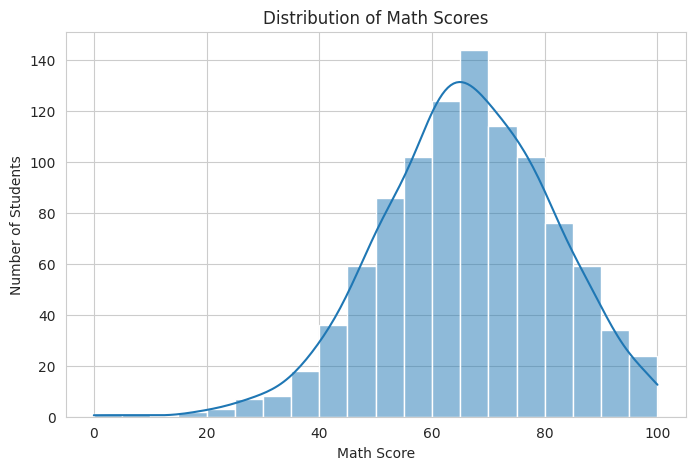

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["math_score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")

plt.show()

16.2 Reading score distribution

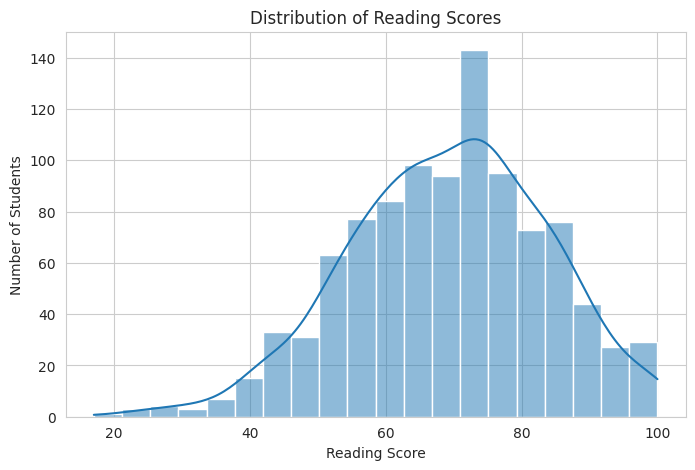

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["reading_score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Reading Scores")
plt.xlabel("Reading Score")
plt.ylabel("Number of Students")

plt.show()

16.3 Writing score distribution

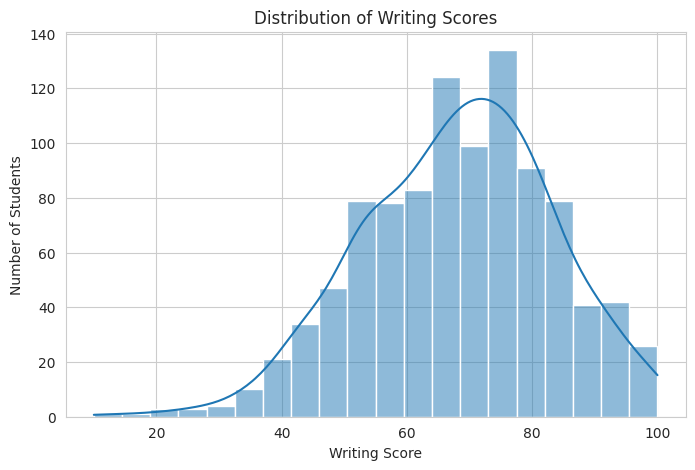

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["writing_score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Writing Scores")
plt.xlabel("Writing Score")
plt.ylabel("Number of Students")

plt.show()

Step 17: Outlier identification using IQR

In [23]:
# Create an empty list for outlier results

outlier_results = []

for col in score_columns:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Subject": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

# Display outlier summary

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Subject,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,math_score,57.00,77.0,20.00,27.000,107.000,8
1,reading_score,59.00,79.0,20.00,29.000,109.000,6
2,writing_score,57.75,79.0,21.25,25.875,110.875,5


Step 18: Outlier identification using Z-score

In [24]:
# Calculate Z-scores for subject marks

z_scores = (
    df[score_columns] -
    df[score_columns].mean()
) / df[score_columns].std()

# Identify observations with absolute Z-score greater than 3

zscore_outliers = (z_scores.abs() > 3)

print("Z-score Outlier Count:")

print(zscore_outliers.sum())

Z-score Outlier Count:
math_score       4
reading_score    4
writing_score    4
dtype: int64


In [25]:
# Identify rows with at least one subject outlier

outlier_rows = zscore_outliers.any(axis=1)

zscore_outlier_records = df.loc[outlier_rows].copy()

display(zscore_outlier_records)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score,percentage,pass_fail_status,performance_category
17,Female,Group B,Some High School,Free/Reduced,None,18,32,28,78,26.000000,26.000000,Fail,Below Average
59,Female,Group C,Some High School,Free/Reduced,None,0,17,10,27,9.000000,9.000000,Fail,Below Average
76,Male,Group E,Some High School,Standard,None,30,26,22,78,26.000000,26.000000,Fail,Below Average
327,Male,Group A,Some College,Free/Reduced,None,28,23,19,70,23.333333,23.333333,Fail,Below Average
596,Male,Group B,High School,Free/Reduced,None,30,24,15,69,23.000000,23.000000,Fail,Below Average
787,Female,Group B,Some College,Standard,None,19,38,32,89,29.666667,29.666667,Fail,Below Average
980,Female,Group B,High School,Free/Reduced,None,8,24,23,55,18.333333,18.333333,Fail,Below Average


Step 19: Generate overall student performance summary

In [26]:
# Generate overall performance statistics

print("STUDENT PERFORMANCE SUMMARY")
print("----------------------------------")

print("Total Students:", len(df))

print(
    "Average Math Score:",
    round(df["math_score"].mean(), 2)
)

print(
    "Average Reading Score:",
    round(df["reading_score"].mean(), 2)
)

print(
    "Average Writing Score:",
    round(df["writing_score"].mean(), 2)
)

print(
    "Average Total Score:",
    round(df["total_score"].mean(), 2)
)

print(
    "Average Percentage:",
    round(df["percentage"].mean(), 2)
)

print(
    "Pass Students:",
    (df["pass_fail_status"] == "Pass").sum()
)

print(
    "Fail Students:",
    (df["pass_fail_status"] == "Fail").sum()
)

print(
    "Highest Total Score:",
    df["total_score"].max()
)

print(
    "Lowest Total Score:",
    df["total_score"].min()
)

STUDENT PERFORMANCE SUMMARY
----------------------------------
Total Students: 1000
Average Math Score: 66.09
Average Reading Score: 69.17
Average Writing Score: 68.05
Average Total Score: 203.31
Average Percentage: 67.77
Pass Students: 949
Fail Students: 51
Highest Total Score: 300
Lowest Total Score: 27


Step 20: Subject-wise performance comparison

In [27]:
# Calculate subject-wise average scores

subject_average = df[score_columns].mean()

print("Subject-wise Average Scores:")

display(subject_average)

Subject-wise Average Scores:


,0
math_score,66.089
reading_score,69.169
writing_score,68.054


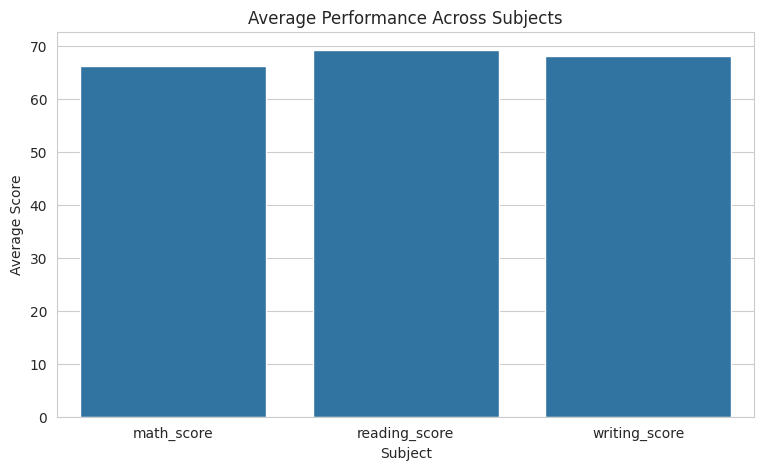

In [28]:
# Visualize subject-wise average scores

plt.figure(figsize=(9, 5))

sns.barplot(
    x=subject_average.index,
    y=subject_average.values
)

plt.title("Average Performance Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.show()

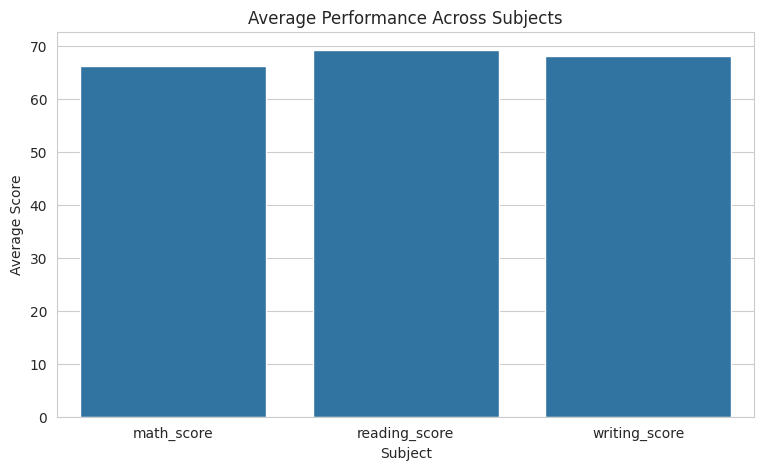

In [29]:
# Visualize subject-wise average scores

plt.figure(figsize=(9, 5))

sns.barplot(
    x=subject_average.index,
    y=subject_average.values
)

plt.title("Average Performance Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.show()

Step 21: Export the processed dataset

In [30]:
# Save the final processed dataset

df.to_csv(
    "student_performance_processed.csv",
    index=False
)

print("Processed dataset exported successfully!")

Processed dataset exported successfully!


Step 22: Export statistical and outlier reports

In [33]:
# Export subject statistical summary

subject_statistics = df[score_columns].describe().T

subject_statistics.to_csv(
    "subject_statistics.csv"
)

print("Subject statistics exported successfully!")

# Export outlier summary

outlier_summary.to_csv(
    "student_score_outlier_summary.csv",
    index=False
)

print("Outlier summary exported successfully!")

# Export pass/fail summary

pass_fail_summary = (
    df["pass_fail_status"]
    .value_counts()
    .reset_index()
)

pass_fail_summary.columns = [
    "Status",
    "Student_Count"
]

pass_fail_summary.to_csv(
    "pass_fail_summary.csv",
    index=False
)

display(pass_fail_summary)


Subject statistics exported successfully!
Outlier summary exported successfully!


,Status,Student_Count
0,Pass,949
1,Fail,51
